# Домашняя работа 5. Банк просит модель для выдачи кредитов

Банк хочет, чтобы заявки на кредит сначала смотрела модель: вернёт клиент деньги или нет.
У каждого из вас свои **800 прошлых заявок** (от фамилии зависят сами заявки и то, какие 600 из них попали в обучение, а какие 200 — в тест).
Про каждую заявку известно, вернул ли клиент кредит; не вернули примерно 30%.

**Основная часть** (обязательно, задания 1–3): прочитать правило, которое придумало дерево; честно выбрать модель; найти ловушку в данных.

**Дополнительно** (по желанию, задания 4–5 — для тех, кому интересно глубже): объяснить клиенту, почему ему отказали,
и сверить всё с тем, как банк (генератор данных) устроен на самом деле. Работа засчитывается и без них.

Срок — до следующего занятия. Работа засчитывается после короткой устной защиты: ноутбук открыт,
преподаватель просит поменять глубину дерева и объяснить, что изменилось.
Обсуждать идеи можно, передавать код и ответы нельзя.

## Что сдать

1. Все `# TODO` основной части выполнены, ноутбук проходит сверху вниз (*Restart & Run All*), ячейки «Проверка» заданий 1–3 печатают «пройдена». В дополнительных заданиях, которые не делаете, оставьте `...` — ноутбук всё равно пройдёт до конца. Файл назван так, как печатает ячейка варианта (например, `hw05_Ivanov.ipynb`).
2. Под каждым сделанным заданием — **Вывод** в 1–3 предложения **с числами** из вашего варианта.
3. Последняя ячейка печатает строку `СВОДКА …` — по ней сверяются ваши числа с эталоном. Её не меняйте.

Главное правило: **тест открываем только в конце задания 2**. Модель выбираем по кросс-валидации на обучении.

In [ ]:
# Служебная ячейка: импорты, стиль графиков, файлы курса (варианты и генератор заявок).
import inspect, re, sys, pathlib, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True

COURSE_FILES_URL = "https://raw.githubusercontent.com/sharipovaka/ml_labs/main/notebooks"


def course_file(name, folder=""):
    # файл курса: ищем рядом (и в папке data), иначе скачиваем из репозитория курса
    for parent in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents][:4]:
        for candidate in (parent / name, parent / "data" / name):
            if candidate.exists():
                return candidate
    urllib.request.urlretrieve(f"{COURSE_FILES_URL}/{folder}{name}", name)
    return pathlib.Path(name)


def draw_tree(model, feature_names, fontsize=9):
    # plot_tree; числа в value — целыми (sklearn иногда печатает «51.0»)
    for box in plot_tree(model, feature_names=feature_names, class_names=["вернул", "не вернул"],
                         filled=True, fontsize=fontsize):
        box.set_text(re.sub(r"(\d+)\.0(?=[,\]])", r"\1", box.get_text()))


sys.path.insert(0, str(course_file("variants.py").parent))
sys.path.insert(0, str(course_file("credit_data.py").parent))
from variants import get_variant, submission_name  # noqa: E402
from credit_data import make_applications  # noqa: E402

## Индивидуальный вариант

Впишите фамилию так, как в списке группы. От строки зависят данные. Регистр, лишние пробелы и «ё»/«е» роли не играют. Однофамильцам нужно добавить инициал (`Петрова А.`).

От фамилии зависят сами заявки и разбиение на обучение и тест. Остальные поля варианта в этой работе не нужны.

In [ ]:
STUDENT = "Фамилия"   # <-- впишите свою фамилию

assert STUDENT.strip() != "Фамилия", "Впишите свою фамилию в переменную STUDENT"

VARIANT = get_variant(STUDENT, lab=5)
print("seed данных:", VARIANT["seed"])
print("Сдавать под именем:", submission_name(STUDENT, lab=5))

### Данные

| столбец | что это |
|---|---|
| `age` | возраст |
| `income` | доход, тыс. руб. в месяц |
| `experience` | стаж на текущей работе, лет |
| `amount` | сумма кредита, тыс. руб. |
| `payment` | ежемесячный платёж в % от дохода (кредит на 3 года, переплата 25%) |
| `n_loans` | сколько ещё кредитов сейчас платит |
| `past_delays` | сколько было просрочек по прошлым кредитам |
| `collateral` | есть залог (1/0) |
| `dependents` | иждивенцев (дети и т. п.) |
| `zodiac` | знак зодиака (1–12) |
| `default` | **ответ: 1 — не вернул**, 0 — вернул |

В таблице есть ещё `app_id` (номер заявки) и `delays_now` (просрочки по этому кредиту) — они понадобятся в задании 3, в признаки их не берём.

`X_train`, `y_train` — 600 заявок для обучения; `X_test`, `y_test` — 200 для теста. **Считайте, что теста у вас нет** до конца задания 2.
`cv5` — пять блоков кросс-валидации; они одинаковы у всех и во всех заданиях, иначе числа не совпадут с проверкой.

In [ ]:
FEATURES = ["age", "income", "experience", "amount", "payment", "n_loans", "past_delays", "collateral", "dependents", "zodiac"]

apps = make_applications(800, seed=VARIANT["seed"])   # ваши 800 заявок
train, test = train_test_split(apps, test_size=0.25, random_state=VARIANT["seed"], stratify=apps["default"])
X_train, y_train = train[FEATURES], train["default"].to_numpy()
X_test, y_test = test[FEATURES], test["default"].to_numpy()
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)

print("обучение:", X_train.shape, " тест:", X_test.shape)
print("доля невозвратов в обучении:", round(y_train.mean(), 3),
      " → правило «всем выдать» угадывает", round(1 - y_train.mean(), 3))
apps.head()

---
# Основная часть

## Задание 1. Правило выдачи

Банку нужно правило, которое кредитный менеджер прочитает без компьютера. Дерево глубины 2 — это и есть такое правило: два вопроса подряд.

1. Обучите `DecisionTreeClassifier(max_depth=2, random_state=0)` на своём обучении → `tree2` (код рисунка уже есть).
2. По рисунку впишите вопросы дерева — признак и порог:
   - `split_feature`, `split_threshold` — вопрос в корне;
   - `left_feature`, `left_threshold` — вопрос в левом узле (туда уходят ответившие «да» на вопрос в корне);
   - `right_feature`, `right_threshold` — вопрос в правом узле.

   Порог переписывайте как на рисунке: `income <= 52.5` → признак `"income"`, порог `52.5`.
3. `worst_leaf_share` — доля невозвратов в самом рискованном листе (где она **наибольшая**). В рамке листа `samples` — сколько заявок,
   `value = [вернули, не вернули]`. Впишите дробью из чисел рисунка: например, `worst_leaf_share = 47 / 61`.

In [ ]:
tree2 = ...   # TODO: дерево глубины 2, random_state=0, обученное на X_train, y_train

plt.figure(figsize=(14, 6))
draw_tree(tree2, FEATURES, fontsize=11)
plt.title("Дерево глубины 2 на вашем обучении")
plt.show()

In [ ]:
# TODO: впишите по рисунку (признак — строкой, например "income"; порог — числом)
split_feature, split_threshold = ..., ...
left_feature, left_threshold = ..., ...
right_feature, right_threshold = ..., ...
worst_leaf_share = ...   # дробью: не вернули / samples

In [ ]:
# Проверка задания 1 (не меняйте эту ячейку): сверка с вашим деревом tree2
assert isinstance(tree2, DecisionTreeClassifier) and tree2.get_depth() == 2, "tree2: дерево глубины 2"
_t = tree2.tree_
assert _t.n_node_samples[0] == len(X_train), "tree2: обучайте на X_train, y_train"
for _what, _node, (_f, _thr) in [
    ("корень", 0, (split_feature, split_threshold)),
    ("левый узел", _t.children_left[0], (left_feature, left_threshold)),
    ("правый узел", _t.children_right[0], (right_feature, right_threshold)),
]:
    assert _f == FEATURES[_t.feature[_node]], f"{_what}: признак {_f!r} не совпал с рисунком"
    assert np.isclose(float(_thr), _t.threshold[_node], atol=2e-3), f"{_what}: порог {_thr} не совпал с рисунком"
_leaf = _t.children_left == -1
_share = (_t.value[_leaf, 0, 1] / _t.value[_leaf, 0].sum(axis=1)).max()
assert np.isclose(float(worst_leaf_share), _share), "worst_leaf_share: в самом рискованном листе — не вернули / samples"
print("Проверка задания 1 пройдена")

**Вывод.** *(Запишите правило для кредитного менеджера словами, без кода: «если платёж больше …% дохода и …, то …».
В какой группе риск самый большой и похож ли такой вопрос на то, что спросил бы живой сотрудник банка?)*

---
## Задание 2. Какую модель взять

Два кандидата: **лучшее дерево** (глубину подбираем) и **лес**. Сравниваем по кросс-валидации `cv5` на обучении, тест не трогаем.
Мера — доля верных ответов (её считают `score` и `cross_val_score`). Сравнивайте с правилом «всем выдать» из ячейки данных — модель должна быть лучше него.

1. Для глубины $d = 1, \dots, 10$ дерево `DecisionTreeClassifier(max_depth=d, random_state=0)`: средняя доля верных
   по `cross_val_score(…, cv=cv5)` → `cv_acc` (таблица и график уже написаны).
2. `best_depth` — глубина с наибольшей `cv_acc`, `cv_tree` — эта доля.
3. Лес `RandomForestClassifier(n_estimators=200, random_state=0)` → `cv_rf`, тоже по `cv5`.
4. `best_model` — `"дерево"` или `"лес"`: у кого больше доля по кросс-валидации (посмотрите в напечатанную таблицу).
   Только теперь **один раз** открываем тест: обучите выбранную модель на всём обучении → доля верных на тесте `test_best`.

In [ ]:
depths = np.arange(1, 11)
cv_acc = []
for d in depths:
    # TODO: добавьте в cv_acc среднюю долю верных по кросс-валидации cv5 у дерева глубины d (random_state=0) — как в лабе
    ...
cv_acc = np.array(cv_acc)
best_depth = ...  # TODO: глубина (число от 1 до 10) с наибольшей cv_acc
cv_tree = ...     # TODO: наибольшая cv_acc

plt.plot(depths, cv_acc, "s-", label="кросс-валидация")
plt.axhline(1 - y_train.mean(), c="gray", ls="--", label="«всем выдать»")
plt.axvline(best_depth, c="k", ls=":", label=f"лучшая глубина: {best_depth}")
plt.xticks(depths)
plt.xlabel("глубина дерева")
plt.ylabel("доля верных (кросс-валидация)")
plt.legend()
plt.show()

In [ ]:
cv_rf = ...   # TODO: средняя доля верных леса (200 деревьев, random_state=0) по кросс-валидации cv5

models = {
    "дерево": DecisionTreeClassifier(max_depth=best_depth, random_state=0),
    "лес": RandomForestClassifier(n_estimators=200, random_state=0),
}
cv_scores = {"дерево": cv_tree, "лес": cv_rf}
print(pd.Series(cv_scores).round(3).to_string())

best_model = ...   # TODO: "дерево" или "лес" — по таблице выше
test_best = ...    # TODO: models[best_model] обучить на всём обучении (fit) и посчитать долю верных на тесте (score)
print("выбрана:", best_model, " тест:", round(test_best, 3))

In [ ]:
# Проверка задания 2 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
assert len(cv_acc) == 10, "по одному числу на каждую глубину 1..10"
assert ((0 < cv_acc) & (cv_acc <= 1)).all(), "cv_acc — доли верных, от 0 до 1"
assert cv_acc[-1] < 0.9, "у глубины 10 больше 0.9 — похоже на долю на обучении, а нужна кросс-валидация"
assert np.isclose(dict(zip(depths, cv_acc)).get(best_depth, -1), cv_acc.max()), "best_depth — глубина (от 1 до 10) с наибольшей cv_acc"
assert np.isclose(cv_tree, cv_acc.max()), "cv_tree — наибольшая cv_acc"
assert 0 < cv_rf <= 1, "cv_rf — доля верных, от 0 до 1"
assert best_model == max(cv_scores, key=cv_scores.get), "модель выбирают по кросс-валидации, а не по тесту"
assert 0 < test_best <= 1, "test_best — доля верных на тесте, от 0 до 1"
print("Проверка задания 2 пройдена")

**Вывод.** *(2–3 предложения с числами: какая модель лучше по кросс-валидации и на сколько она лучше правила «всем выдать»;
сильно ли доля на тесте отличается от кросс-валидации.)*

---
## Задание 3. Детектив: слишком хорошо

Стажёр банка взял **все** столбцы таблицы, обучил лес и радостно сообщил: «точность 98%!». Разберёмся, что он сделал не так.

`cv_leak` — доля верных по кросс-валидации `cv5` у леса `RandomForestClassifier(n_estimators=200, random_state=0)`
на всех столбцах `ALL`. Важность по Джини уже посчитана; `leak_feature` — самый важный столбец.

In [ ]:
ALL = ["app_id"] + FEATURES + ["delays_now"]   # как у стажёра: все столбцы, кроме ответа
cv_leak = ...   # TODO: cross_val_score леса (200 деревьев, random_state=0) на train[ALL], y_train, cv=cv5, среднее
print("кросс-валидация на всех столбцах:", round(cv_leak, 3))

rf_all = RandomForestClassifier(n_estimators=200, random_state=0).fit(train[ALL], y_train)
mdi_all = pd.Series(rf_all.feature_importances_, index=ALL)
leak_feature = ...   # TODO: столбец с наибольшей важностью mdi_all
print("главный по Джини:", leak_feature, round(mdi_all.max(), 3))

Утечка: столбец, который становится известен только после выдачи кредита. У новой заявки его ещё нет, так что эти 98% — самообман.

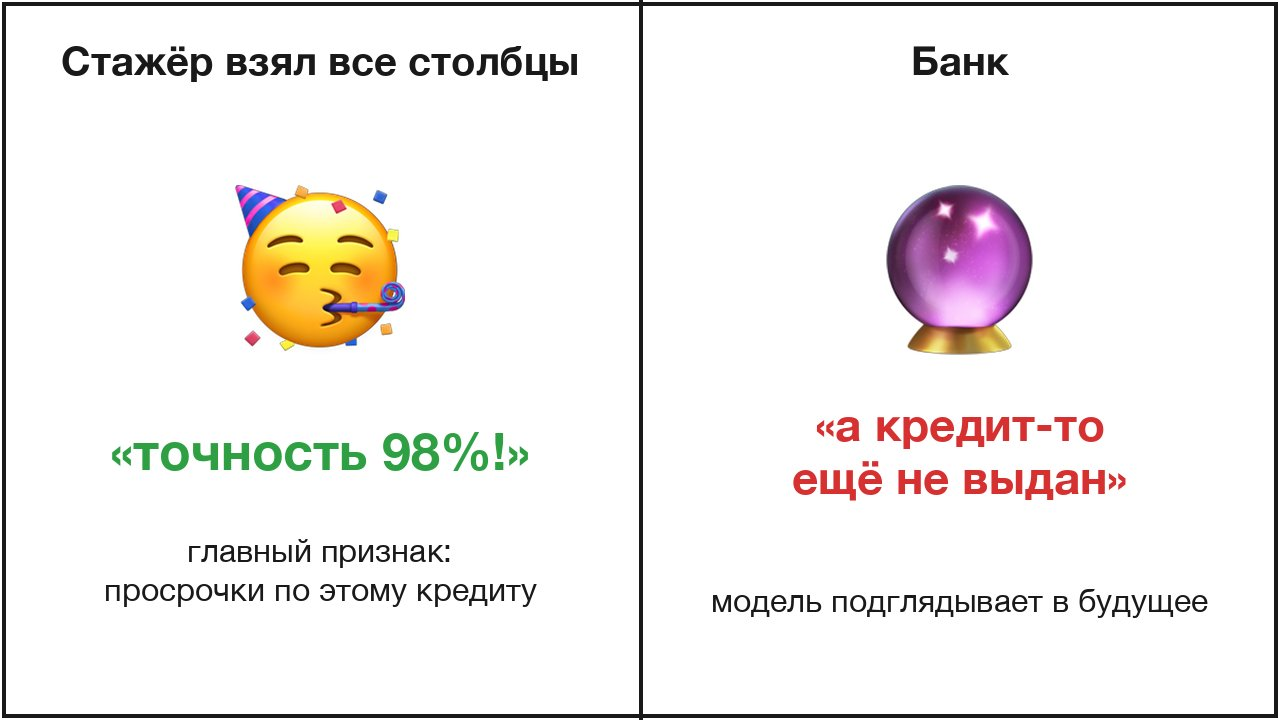

In [ ]:
# Проверка задания 3 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
assert 0 < cv_leak <= 1, "cv_leak — доля верных, от 0 до 1"
assert cv_leak > cv_rf, "на всех столбцах лес должен угадывать лучше, чем в задании 2: посмотрите, что за столбцы в ALL"
assert leak_feature in mdi_all and np.isclose(mdi_all[leak_feature], mdi_all.max()), "leak_feature: столбец с наибольшей mdi_all"
print("Проверка задания 3 пройдена")

**Вывод.** *(2–3 предложения: почему `delays_now` даёт почти 100% и почему в настоящем банке такой модели не бывает —
когда известны просрочки по кредиту, который ещё только просят? Какие столбцы вы бы выкинули?)*

---
# Дополнительно (по желанию)

Два задания для тех, кому интересно разобраться глубже. Работа засчитывается и без них;
если не делаете — оставьте `...` в ячейках, ноутбук всё равно пройдёт до конца.

## Задание 4. «Почему мне отказали?»

Пришёл клиент. Банк одобряет кредит, если вероятность невозврата **меньше 0.5**. Модель — лес `rf` на честных признаках (без `app_id` и `delays_now`).
Функция `p_default(rf, ...)` возвращает вероятность невозврата у клиента; в скобках можно поменять что-то в заявке,
например `p_default(rf, amount=500)` или `p_default(rf, collateral=1, n_loans=0)`. Платёж `payment` пересчитывается сам.

1. `p_client` — вероятность невозврата у клиента без изменений.
2. Меняйте по одному признаку: сумма, залог, число кредитов, доход, … — и ищите, что даст одобрение. Если одного мало — попробуйте два.
   Числом это не проверяется, нужен вывод. Для смеха проверьте и знак зодиака.

In [ ]:
CLIENT = dict(age=27, income=60, experience=1.5, amount=700, n_loans=2, past_delays=1,
              collateral=0, dependents=1, zodiac=7)


def p_default(model, **changes):
    # вероятность невозврата у клиента; changes — что поменять в заявке, например amount=500
    c = {**CLIENT, **changes}
    c["payment"] = round(100 * c["amount"] * 1.25 / 36 / c["income"])   # платёж пересчитывается сам
    return model.predict_proba(pd.DataFrame([c])[FEATURES])[0, 1]


rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
p_client = ...   # TODO: вероятность невозврата у клиента без изменений
if p_client is not ...:   # задание сделано
    print("платёж:", round(100 * CLIENT["amount"] * 1.25 / 36 / CLIENT["income"]), "% дохода;  вероятность невозврата:",
          round(p_client, 2), "→", "одобрить" if p_client < 0.5 else "отказать")

In [ ]:
# TODO: пробуйте изменения, например:
# print(p_default(rf, amount=500))
...

In [ ]:
# Проверка задания 4 (не меняйте эту ячейку)
if p_client is ...:
    print("Задание 4 не делали — пропускаем")
else:
    assert 0 <= p_client <= 1, "p_client — вероятность, от 0 до 1"
    print("Проверка задания 4 пройдена")

**Вывод.** *(2–3 предложения: почему клиенту отказали; какое самое маленькое изменение даёт одобрение и с какой вероятностью;
повлиял ли знак зодиака. Что бы вы посоветовали клиенту?)*

---
## Задание 5. Раскрываем карты

Вот как на самом деле устроены ваши данные — генератор из файла курса `credit_data.py`. Строка `z = …` и `logit = …` — «настоящий банк»:
чем больше `logit`, тем вероятнее невозврат. Плюс в формуле — признак повышает риск, минус — снижает; две и больше прошлых просрочек сильно повышают риск;
`zodiac` в формулу не входит вообще.

Посчитайте перестановочную важность честного леса `rf` на тесте (насколько падает доля верных, если перемешать столбец;
на тесте здесь можно: модель уже выбрана, по тесту ничего не выбираем) → `perm` (Series по `FEATURES`), `top_feature_perm` — самый важный признак,
`perm_zodiac` — важность знака зодиака. Сравните с формулой.

In [ ]:
print(inspect.getsource(make_applications))

In [ ]:
perm = ...               # TODO: перестановочная важность rf на тесте (n_repeats=10, random_state=0) — Series по FEATURES, как в лабе
top_feature_perm = ...   # TODO: признак с наибольшей perm
perm_zodiac = ...        # TODO: важность знака зодиака
if perm is not ...:   # задание сделано
    print("самый важный:", top_feature_perm, " знак зодиака:", round(perm_zodiac, 3))
    perm.sort_values().plot.barh(color=["C3" if f == "zodiac" else "gray" for f in perm.sort_values().index])
    plt.xlabel("падение доли верных, если перемешать (тест)")
    plt.title("Каким признакам верит честный лес (zodiac — красный)")
    plt.show()

In [ ]:
# Проверка задания 5 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
if perm is ...:
    print("Задание 5 не делали — пропускаем")
else:
    assert isinstance(perm, pd.Series) and set(perm.index) == set(FEATURES), "perm — Series с индексом FEATURES"
    assert np.isclose(perm[top_feature_perm], perm.max()), "top_feature_perm — признак с наибольшей perm"
    assert np.isclose(perm_zodiac, perm["zodiac"]), "perm_zodiac — perm у zodiac"
    print("Проверка задания 5 пройдена")

**Вывод.** *(2–3 предложения: какие признаки лес счёл главными и совпадает ли это с формулой генератора;
что со знаком зодиака; совпадает ли с формулой правило из задания 1 и совет клиенту из задания 4?)*

In [ ]:
# Сводка для проверки (не меняйте эту ячейку)
import json
_summary = {"STUDENT": STUDENT}
for _k in ["split_feature", "split_threshold", "left_feature", "left_threshold", "worst_leaf_share",
           "best_depth", "cv_tree", "cv_rf", "best_model", "test_best",
           "cv_leak", "leak_feature", "p_client", "top_feature_perm", "perm_zodiac"]:
    _v = globals().get(_k)
    if _v is None or _v is ...:            # ... — задание не сделано
        _summary[_k] = None
    else:
        _summary[_k] = _v if isinstance(_v, str) else float(_v)
print("СВОДКА", json.dumps(_summary, ensure_ascii=False))